In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report ,confusion_matrix
from tensorflow.keras.models import load_model
import tensorflow as tf
import cv2
import time

In [3]:
dataset_testing = np.load("./datasets/nails_disease_dataset_testing_multi_class.npz")
X_test = dataset_testing["X_test"]
y_test = dataset_testing["y_test"]

In [4]:
np.unique(y_test)

array([0, 1, 2, 3, 4, 5, 6, 7], dtype=int32)

In [5]:
model = load_model("models/multi class classification models/mobilenetv3small/nails_disease_multi_class_classification_model.keras")

In [7]:
X_test_mob_prep = tf.keras.applications.mobilenet_v3.preprocess_input(X_test.copy())

In [9]:
prediction = model.predict(X_test_mob_prep)

13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 361ms/step


In [10]:
y_pred = np.argmax(prediction, axis=1)


In [12]:
print(classification_report(y_pred = y_pred , y_true = y_test))

              precision    recall  f1-score   support

           0       0.99      0.95      0.97        82
           1       0.90      1.00      0.95        18
           2       0.73      0.89      0.80         9
           3       0.82      0.56      0.67        16
           4       0.64      0.58      0.61        12
           5       0.76      1.00      0.86        16
           6       0.92      0.97      0.94       147
           7       0.94      0.86      0.90        92

    accuracy                           0.91       392
   macro avg       0.84      0.85      0.84       392
weighted avg       0.91      0.91      0.91       392



In [15]:
cm = confusion_matrix(y_pred = y_pred , y_true = y_test)
cm

array([[ 78,   0,   0,   0,   0,   0,   0,   4],
       [  0,  18,   0,   0,   0,   0,   0,   0],
       [  0,   1,   8,   0,   0,   0,   0,   0],
       [  0,   0,   3,   9,   1,   3,   0,   0],
       [  0,   1,   0,   2,   7,   2,   0,   0],
       [  0,   0,   0,   0,   0,  16,   0,   0],
       [  1,   0,   0,   0,   3,   0, 142,   1],
       [  0,   0,   0,   0,   0,   0,  13,  79]])

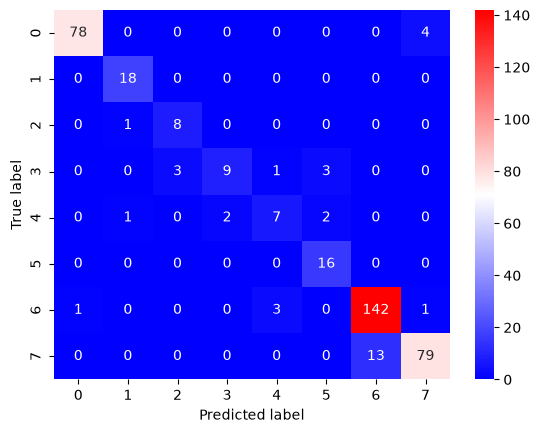

In [16]:
sns.heatmap(cm, annot=True, fmt='g' , cmap = "bwr");
plt.ylabel('True label');
plt.xlabel('Predicted label');

In [18]:
model.evaluate(X_test,y_test)

13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 209ms/step - accuracy: 0.9107 - loss: 0.2615


[0.2614634037017822, 0.9107142686843872]

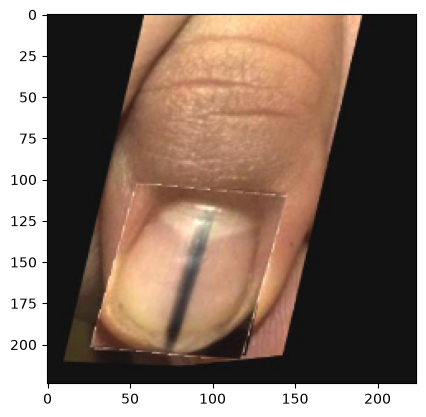

In [25]:
# evaluating model inference time
img = X_test[90]
plt.imshow(img/255);

In [26]:

def benchmark_model(model, image, n_warmup=10, n_runs=500):

    # Warm-up
    for _ in range(n_warmup):
        _ = model.predict(image, verbose=0)

    # Actual benchmark
    times = []

    for _ in range(n_runs):
        start = time.perf_counter()

        _ = model.predict(image, verbose=0)

        end = time.perf_counter()
        times.append(end - start)

    times = np.array(times)

    return {
        "mean_ms": times.mean() * 1000,
        "median_ms": np.median(times) * 1000,
        "std_ms": times.std() * 1000,
        "min_ms": times.min() * 1000,
        "max_ms": times.max() * 1000,
        "images_per_second": 1 / times.mean()
    }

In [27]:
result = benchmark_model(
    model,
    img[np.newaxis,...]
)
result

{'mean_ms': np.float64(224.14215459948173),
 'median_ms': np.float64(204.43954999791458),
 'std_ms': np.float64(72.55635173011754),
 'min_ms': np.float64(114.92000000725966),
 'max_ms': np.float64(776.1470999976154),
 'images_per_second': np.float64(4.461454391686803)}

The inference performance of the proposed nail classification model, developed using MobileNetV3Small, was evaluated by measuring its prediction latency and processing throughput. The model achieved a mean inference latency of 224.14 ms and a median latency of 204.44 ms per image. The standard deviation was 72.56 ms, with observed inference times ranging from 114.92 ms to 776.15 ms. The measured throughput was approximately 4.46 images per second. These results indicate that the model has potential for real-time or near-real-time nail image classification in a CPU-based application, although end-to-end application latency and classification accuracy must be evaluated separately.